# 13 - Uncertainty Budget: How Far to Trust a Species Record

Notebooks 01 to 12 treated the database as if every record deserved the same
trust. This one asks how far a single species can deviate from reference
thermochemistry. Since 0.5.0, `pyglenn` ships a per-species error envelope
exposed by `ThermochemicalCalculator.uncertainty`. The envelope summarises, in a
single temperature-independent set of numbers, the difference between the
bundled NASA polynomials and NIST-JANAF tables: a bias and a two-sigma band for
Cp and H, and an absolute two-sigma band for S.

The plan is short. We start with what the method returns, then measure how much
of the catalogue is actually validated, look at the species the envelope flags, test the
declared band against an independent reference, and finish by propagating the band
into a reaction enthalpy.

In [1]:
import pandas as pd

from pyglenn import ThermochemicalCalculator

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


In [2]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## 1. What the method returns

`uncertainty(species_id, temperature)` returns a dictionary. The temperature is
checked against the species range but does not change the numbers, because the
envelope is one summary for the whole interval.

| key | meaning |
|-----|---------|
| `cp_rel_bias` | mean relative deviation of Cp, in percent |
| `cp_rel_2sigma` | two-sigma relative band of Cp, in percent |
| `h_rel_bias` | mean relative deviation of the standardized enthalpy, in percent |
| `h_rel_2sigma` | two-sigma relative band of H, in percent |
| `s_abs_2sigma` | two-sigma band of S, absolute, in J/(mol K) |
| `n_ref_points` | number of reference points behind the envelope |
| `source` | `nist-janaf` for validated species, `extrapolated` otherwise |

Two properties decide how the envelope may be used. The band does not depend on
temperature: the same numbers come back at 300, 1000 and 3000 K, so one figure
covers an interval where the polynomials change shape. And it is not estimated
species by species across the catalogue. The 2 017 extrapolated records share
only two distinct constants, so their bands are identical to the last digit.


In [3]:
with ThermochemicalCalculator() as calc:
    co2 = calc.get_available_species("CO2", exact_match=True)[0]
    envelope = calc.uncertainty(co2.id, 1000.0)

for key, value in envelope.items():
    print(f"{key:15s}: {value}")

species_id     : 316
species_name   : CO2
temperature    : 1000.0
cp_rel_bias    : 0.1874
cp_rel_2sigma  : 1.4138
h_rel_bias     : 0.0221
h_rel_2sigma   : 0.1668
s_abs_2sigma   : 0.0912
n_ref_points   : 16
source         : nist-janaf


## 2. How much of the catalogue is validated

The label in `source` matters more than the numbers. A validated species was
compared point by point against tabulated reference data. Everything else
carries a default band that came from the validation study, not from a fit to
that particular species.

The figure below puts the split and the band each group carries side by side.


In [4]:
with ThermochemicalCalculator() as calc:
    catalogue = calc.get_available_species("")
    rows = []
    outside = 0
    for s in catalogue:
        low, high = calc.db.get_temperature_bounds(s.id)
        if not low <= 298.15 <= high:
            outside += 1
        env = calc.uncertainty(s.id, 0.5 * (low + high))
        rows.append({
            "species": s.name,
            "source": "missing" if env is None else env["source"],
            "cp_bias": None if env is None else env["cp_rel_bias"],
            "cp_2sigma": None if env is None else env["cp_rel_2sigma"],
        })

bands = pd.DataFrame(rows)
print(f"records whose valid range excludes 298.15 K: {outside}")
bands["source"].value_counts()

records whose valid range excludes 298.15 K: 416


source
extrapolated    2017
nist-janaf        18
Name: count, dtype: int64

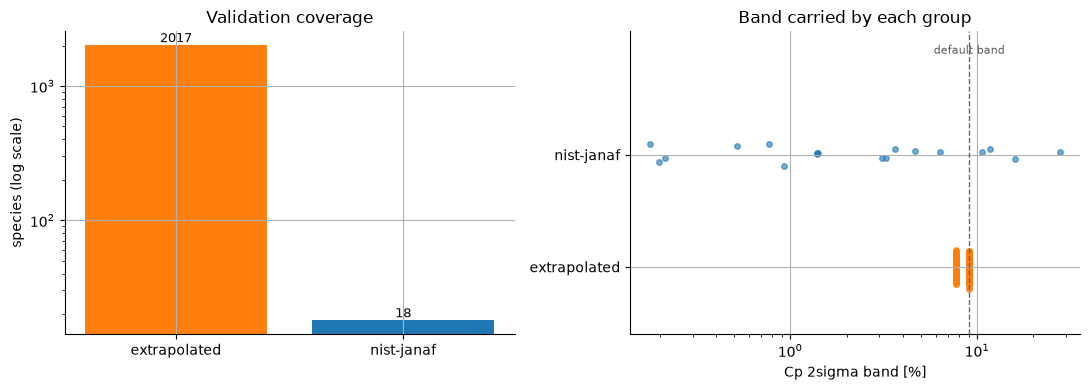

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

counts = bands["source"].value_counts()
tint = {"nist-janaf": "tab:blue", "extrapolated": "tab:orange", "missing": "0.6"}
ax1.bar(counts.index, counts.values, color=[tint[k] for k in counts.index])
ax1.set_yscale("log")
ax1.set_ylabel("species (log scale)")
ax1.set_title("Validation coverage")
for i, v in enumerate(counts.values):
    ax1.annotate(f"{v}", (i, v), ha="center", va="bottom", fontsize=9)

rng = np.random.default_rng(0)
groups = ["extrapolated", "nist-janaf"]
for row, label in enumerate(groups):
    band = bands.loc[bands["source"] == label, "cp_2sigma"].dropna()
    jitter = rng.normal(0.0, 0.05, len(band))
    ax2.scatter(band, row + jitter, s=16, alpha=0.6, color=tint[label])
default_band = bands.loc[bands["source"] == "extrapolated", "cp_2sigma"].median()
ax2.axvline(default_band, color="0.4", ls="--", lw=1)
ax2.annotate("default band", (default_band, 1.9), ha="center", fontsize=8, color="0.35")
ax2.set_xscale("log")
ax2.set_yticks(range(len(groups)))
ax2.set_yticklabels(groups)
ax2.set_ylim(-0.6, 2.1)
ax2.set_xlabel("Cp 2sigma band [%]")
ax2.set_title("Band carried by each group")
plt.tight_layout()
plt.show()

The imbalance is large. Only eighteen species were validated by hand, and the
remaining two thousand and seventeen inherit the default envelope. That is not a defect of
the library, it is a statement about how much work validation costs, and it
should temper any claim about accuracy made for an arbitrary species.

Not every record can even be queried at ambient temperature. In 416 of the 2 035
species, 298.15 K falls outside the valid range, so the call raises instead of
returning a band. The loop above uses the midpoint of each range for that reason.


## 3. Species flagged by the envelope

The envelope earns its keep as a screening device. Among the validated species
used in this labbook, carbon dioxide stays at 1.4 percent on Cp, oxygen at 0.8
and nitrogen at 0.2; water reaches 3.1, and extrapolated entries carry the
default band of about 9 percent.

In [6]:
names = ["CO2", "H2O", "O2", "N2", "CH4", "C2H5OH"]

rows = []
with ThermochemicalCalculator() as calc:
    for name in names:
        s = calc.get_available_species(name, exact_match=True)[0]
        env = calc.uncertainty(s.id, 1000.0)
        rows.append({
            "species": s.name,
            "source": env["source"],
            "Cp bias [%]": env["cp_rel_bias"],
            "Cp 2sigma [%]": env["cp_rel_2sigma"],
            "H 2sigma [%]": env["h_rel_2sigma"],
            "S 2sigma [J/mol/K]": env["s_abs_2sigma"],
        })

envelopes = pd.DataFrame(rows).set_index("species").round(2)
envelopes

,source,Cp bias [%],Cp 2sigma [%],H 2sigma [%],S 2sigma [J/mol/K]
species,,,,,
CO2,nist-janaf,0.190,1.410,0.170,0.090
H2O,nist-janaf,1.100,3.100,1.630,1.170
O2,nist-janaf,0.100,0.770,0.280,0.150
N2,nist-janaf,0.030,0.180,0.020,0.010
CH4,nist-janaf,8.820,27.610,13.550,17.290
C2H5OH,extrapolated,0.000,9.070,4.300,5.100


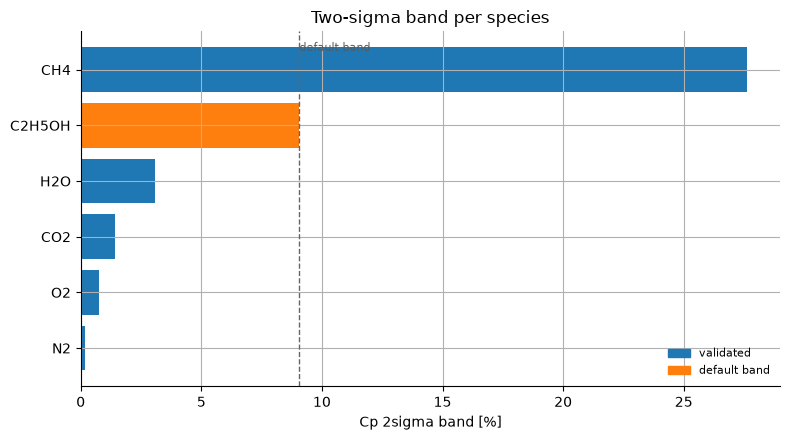

In [7]:
from matplotlib.patches import Patch

order = envelopes.sort_values("Cp 2sigma [%]")
default_band = envelopes.loc[envelopes["source"] == "extrapolated", "Cp 2sigma [%]"].iloc[0]
colour = ["tab:orange" if s == "extrapolated" else "tab:blue" for s in order["source"]]

fig, ax = plt.subplots()
ax.barh(order.index, order["Cp 2sigma [%]"], color=colour)
ax.axvline(default_band, color="0.4", ls="--", lw=1)
ax.annotate("default band", (default_band, len(order) - 0.5), va="top", fontsize=8, color="0.35")
ax.set_xlabel("Cp 2sigma band [%]")
ax.set_title("Two-sigma band per species")
ax.legend(handles=[Patch(color="tab:blue", label="validated"),
                   Patch(color="tab:orange", label="default band")],
          frameon=False, loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

Methane is the exception, at 27.6 percent, one order of magnitude above the
others. A flag of that size does not prove that the record is wrong, but it does
establish where to look first. The next two sections follow that lead: the
anchors at 298.15 K, then a comparison against an independent reference over the
temperature range.

## 4. Following up on a flagged species

The first question for a flagged record is whether the fundamental anchors hold.
Three values are enough: the heat capacity, the entropy and the enthalpy of
formation at 298.15 K. Reference values for methane are widely tabulated, and
the comparison takes one loop.

In [8]:
anchors = {                      # NIST reference values for CH4(g)
    "Cp(298.15 K) [J/mol/K]": 35.69,
    "S(298.15 K) [J/mol/K]": 186.25,
    "dHf(298.15 K) [kJ/mol]": -74.87,
}

with ThermochemicalCalculator() as calc:
    ch4 = calc.get_available_species("CH4", exact_match=True)[0]
    props = calc.calculate_properties(ch4.id, 298.15)
    computed = {
        "Cp(298.15 K) [J/mol/K]": props.cp,
        "S(298.15 K) [J/mol/K]": props.s,
        "dHf(298.15 K) [kJ/mol]": props.h_relative / 1000.0,
    }

for label, reference in anchors.items():
    dev = 100.0 * (computed[label] - reference) / abs(reference)
    print(f"{label:24s} pyglenn {computed[label]:9.3f}   NIST {reference:9.3f}   dev {dev:+.3f} %")

Cp(298.15 K) [J/mol/K]   pyglenn    35.691   NIST    35.690   dev +0.004 %
S(298.15 K) [J/mol/K]    pyglenn   186.371   NIST   186.250   dev +0.065 %
dHf(298.15 K) [kJ/mol]   pyglenn   -74.600   NIST   -74.870   dev +0.361 %


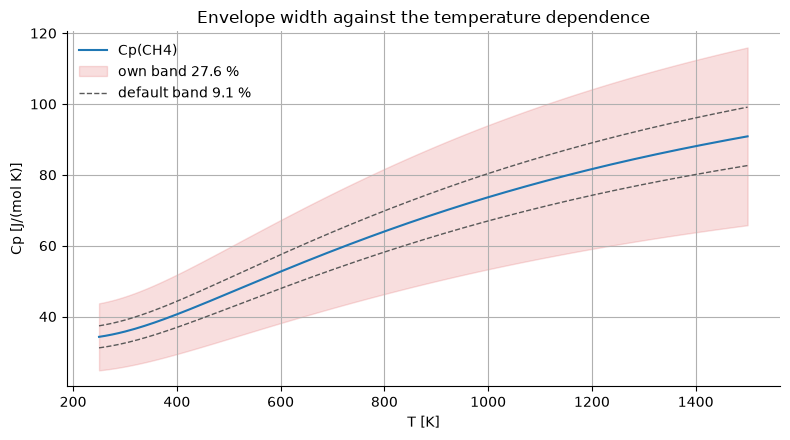

In [9]:
temps = np.linspace(250.0, 1500.0, 200)
with ThermochemicalCalculator() as calc:
    ch4_id = calc.get_available_species("CH4", exact_match=True)[0].id
    ethanol_id = calc.get_available_species("C2H5OH", exact_match=True)[0].id
    cp = np.array([calc.calculate_properties(ch4_id, T).cp for T in temps])
    own = calc.uncertainty(ch4_id, 1000.0)["cp_rel_2sigma"]
    default_band = calc.uncertainty(ethanol_id, 298.15)["cp_rel_2sigma"]

fig, ax = plt.subplots()
ax.plot(temps, cp, color="tab:blue", label="Cp(CH4)")
ax.fill_between(temps, cp * (1 - own / 100), cp * (1 + own / 100),
                color="tab:red", alpha=0.15, label="own band {:.1f} %".format(own))
for sign in (+1, -1):
    ax.plot(temps, cp * (1 + sign * default_band / 100), color="0.35", ls="--", lw=1,
            label="default band {:.1f} %".format(default_band) if sign > 0 else None)
ax.set_xlabel("T [K]")
ax.set_ylabel("Cp [J/(mol K)]")
ax.set_title("Envelope width against the temperature dependence")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

All three anchors land close to the reference: 0.004 percent on the heat
capacity, 0.07 percent on the entropy and 0.36 percent on the enthalpy of
formation. The record is sound near ambient temperature, and the flagged band
cannot be explained by a shifted formation enthalpy or a wrong entropy constant.
The corridor plot adds the other consequence: a band measured once becomes a
wedge that widens with temperature.

## 5. An independent check of the declared band

The envelope states what the polynomial is supposed to miss, not what it
actually misses. Measuring the latter needs a reference outside the bundled
database. NIST publishes Shomate coefficients for the same species, as a
separate fit to the same calorimetric data, and one segment covers the range used
in most of this labbook.

The comparison evaluates both descriptions of Cp on the same grid, from the lower
temperature of each segment to its upper limit. The last column divides the
declared two-sigma band by the largest deviation actually observed.

In [10]:
# NIST Shomate coefficients for Cp (A, B, C, D, E) and the segment limits
SHOMATE = {
    "N2":  ((28.98641, 1.853978, -9.647459, 16.63537, 0.000117), 200.0, 500.0),
    "O2":  ((31.32234, -20.23531, 57.86644, -36.50624, -0.007374), 200.0, 700.0),
    "CO2": ((24.99735, 55.18696, -33.69137, 7.948387, -0.136638), 298.0, 1200.0),
    "H2O": ((30.09200, 6.832514, 6.793435, -2.534480, 0.082139), 298.0, 1700.0),
    "CH4": ((-0.703029, 108.4773, -42.52157, 5.862788, 0.678565), 298.0, 1300.0),
}


def shomate_cp(coefficients, temperature):
    a, b, c, d, e = coefficients
    t = temperature / 1000.0
    return a + b * t + c * t**2 + d * t**3 + e / t**2


rows = []
with ThermochemicalCalculator() as calc:
    for name, (coefficients, low, high) in SHOMATE.items():
        species = calc.get_available_species(name, exact_match=True)[0]
        grid = np.linspace(low, high, 60)
        library = np.array([calc.calculate_properties(species.id, T).cp for T in grid])
        reference = shomate_cp(coefficients, grid)
        relative = 100.0 * (library - reference) / reference
        envelope = calc.uncertainty(species.id, 0.5 * (low + high))
        rows.append({
            "species": name,
            "range [K]": f"{low:.0f}-{high:.0f}",
            "max |dev| [%]": np.abs(relative).max(),
            "declared 2sigma [%]": envelope["cp_rel_2sigma"],
            "ratio": envelope["cp_rel_2sigma"] / np.abs(relative).max(),
        })

check = pd.DataFrame(rows).set_index("species").round(2)
check

,range [K],max |dev| [%],declared 2sigma [%],ratio
species,,,,
N2,200-500,0.020,0.180,10.980
O2,200-700,0.090,0.770,8.130
CO2,298-1200,0.060,1.410,22.730
H2O,298-1700,0.770,3.100,4.050
CH4,298-1300,4.030,27.610,6.850


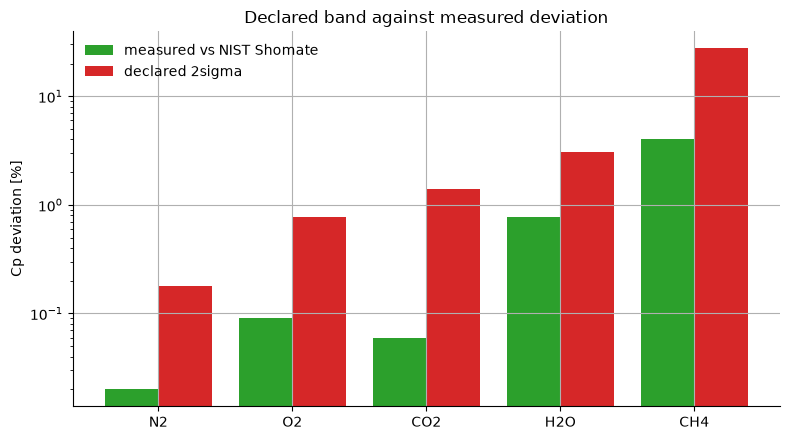

In [11]:
fig, ax = plt.subplots()
position = np.arange(len(check))
ax.bar(position - 0.2, check["max |dev| [%]"], width=0.4,
       color="tab:green", label="measured vs NIST Shomate")
ax.bar(position + 0.2, check["declared 2sigma [%]"], width=0.4,
       color="tab:red", label="declared 2sigma")
ax.set_yscale("log")
ax.set_xticks(position)
ax.set_xticklabels(check.index)
ax.set_ylabel("Cp deviation [%]")
ax.set_title("Declared band against measured deviation")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

The declared band is four to twenty-three times larger than the largest
deviation found here, and the discrepancy is too systematic to be noise. The
ordering, however, survives: methane ranks worst and nitrogen best, so the
envelope still works as a screen. It is not a calibrated error bar, and quoting
it as one, say plus or minus 1.4 percent on carbon dioxide, overstates the error
by more than an order of magnitude.

Where the gap comes from is not documented. The published summary gives the band
and the number of reference points, not the residuals behind them. Range is the
likely origin, since sixteen points spread over an interval that reaches 6000 K
include temperatures where the polynomial is extrapolating. The check above does
not settle that question, and it does not need to. Inside the window this labbook
works in, the band is conservative and the ranking of species is trustworthy.

## 6. Propagating the band into a reaction enthalpy

For a linear combination such as a reaction enthalpy, the bands combine in
quadrature with the stoichiometric coefficients as weights, provided the errors
are independent. The example below takes the complete combustion of methane at
298.15 K, treats the relative band of H as if it applied to the standardized
enthalpy of each species, and keeps the biases in a separate column so their
effect can be measured.

In [12]:
reaction = {"CH4": -1.0, "O2": -2.0, "CO2": +1.0, "H2O": +2.0}

terms = []
with ThermochemicalCalculator() as calc:
    for name, nu in reaction.items():
        species = calc.get_available_species(name, exact_match=True)[0]
        h = calc.calculate_properties(species.id, 298.15).h_relative / 1000.0
        envelope = calc.uncertainty(species.id, 298.15)
        terms.append({
            "species": name,
            "nu": nu,
            "H [kJ/mol]": h,
            "2sigma [kJ/mol]": abs(h) * envelope["h_rel_2sigma"] / 100.0,
            "source": envelope["source"],
            "h_rel_bias [%]": envelope["h_rel_bias"],
        })

table = pd.DataFrame(terms).set_index("species")
table["|nu| x 2sigma [kJ/mol]"] = (table["nu"] * table["2sigma [kJ/mol]"]).abs()

dH = float((table["nu"] * table["H [kJ/mol]"]).sum())
band = float((table["|nu| x 2sigma [kJ/mol]"] ** 2).sum() ** 0.5)
bias_shift = float((table["nu"] * table["H [kJ/mol]"] * table["h_rel_bias [%]"] / 100.0).sum())

print(table.round(2))
print(f"\nDelta H_rxn(298.15 K) = {dH:8.1f} kJ/mol")
print(f"combined 2sigma       = {band:8.1f} kJ/mol  ({100 * band / abs(dH):.1f} % of the enthalpy)")
print(f"systematic shift from the biases = {bias_shift:+.2f} kJ/mol")

            nu  H [kJ/mol]  2sigma [kJ/mol]      source  h_rel_bias [%]  \
species                                                                   
CH4     -1.000     -74.600           10.110  nist-janaf           4.610   
O2      -2.000      -0.000            0.000  nist-janaf           0.090   
CO2      1.000    -393.510            0.660  nist-janaf           0.020   
H2O      2.000    -241.830            3.940  nist-janaf           0.530   

         |nu| x 2sigma [kJ/mol]  
species                          
CH4                      10.110  
O2                        0.000  
CO2                       0.660  
H2O                       7.890  

Delta H_rxn(298.15 K) =   -802.6 kJ/mol
combined 2sigma       =     12.8 kJ/mol  (1.6 % of the enthalpy)
systematic shift from the biases = +0.77 kJ/mol


In [13]:
reaction = {"C2H5OH": -1.0, "O2": -3.0, "CO2": +2.0, "H2O": +3.0}

contributions = {}
with ThermochemicalCalculator() as calc:
    for name, nu in reaction.items():
        species = calc.get_available_species(name, exact_match=True)[0]
        h = calc.calculate_properties(species.id, 298.15).h_relative / 1000.0
        envelope = calc.uncertainty(species.id, 298.15)
        contributions[name] = (nu, abs(h) * envelope["h_rel_2sigma"] / 100.0, envelope["source"])

quadrature = sum((nu * sigma) ** 2 for nu, sigma, _ in contributions.values()) ** 0.5
linear = sum(abs(nu) * sigma for nu, sigma, _ in contributions.values())

for name, (nu, sigma, source) in contributions.items():
    print(f"{name:8s} nu={nu:+4.1f}  2sigma={sigma:6.2f} kJ/mol  ({source})")
print(f"quadrature          {quadrature:6.2f} kJ/mol")
print(f"perfect correlation {linear:6.2f} kJ/mol")

C2H5OH   nu=-1.0  2sigma= 10.10 kJ/mol  (extrapolated)
O2       nu=-3.0  2sigma=  0.00 kJ/mol  (nist-janaf)
CO2      nu=+2.0  2sigma=  0.66 kJ/mol  (nist-janaf)
H2O      nu=+3.0  2sigma=  3.94 kJ/mol  (nist-janaf)
quadrature           15.61 kJ/mol
perfect correlation  23.24 kJ/mol


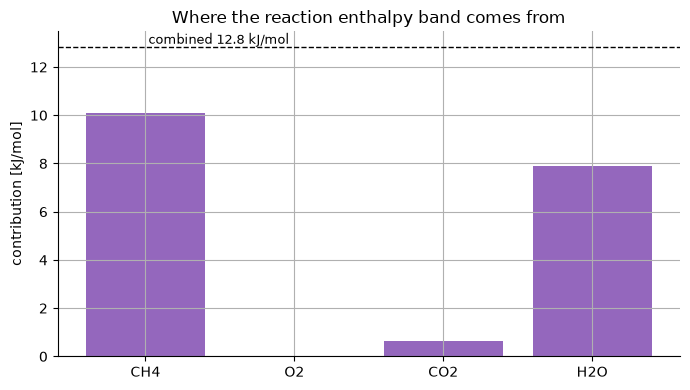

In [14]:
contrib = table["|nu| x 2sigma [kJ/mol]"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(contrib.index, contrib.values, color="tab:purple")
ax.axhline(band, color="k", ls="--", lw=1)
ax.annotate("combined {:.1f} kJ/mol".format(band), (0.02, band), va="bottom", fontsize=9)
ax.set_ylabel("contribution [kJ/mol]")
ax.set_title("Where the reaction enthalpy band comes from")
plt.tight_layout()
plt.show()

The combined band of roughly 13 kJ/mol corresponds to 1.6 percent of the
reaction enthalpy, and almost all of it comes from the fuel. This asymmetry is
typical: the species with the largest formation enthalpy dominates the budget,
so a validated fuel is worth more than a validated product.

Two corrections matter when the recipe is applied elsewhere. The biases are
systematic rather than random, and adding them shifts this enthalpy by about
0.8 kJ/mol, which the quadrature alone does not show. And the quadrature assumes
independent errors, which holds here only because all four species are validated.
The 2 017 extrapolated records share a single constant, so two of them are
perfectly correlated and their contributions add linearly. For the combustion of
ethanol, whose fuel is extrapolated, quadrature gives 15.6 kJ/mol against 23.2
kJ/mol for linear addition, a difference of nearly fifty percent.

## 7. What to do with it

Check the source label before trusting a species that drives a conclusion. When
the record is validated, quote the band next to the computed value, together with
the range it was checked over. When it is extrapolated, say so, and treat a
reaction budget for such a species as an upper bound rather than a measurement.
When a band looks anomalous, compare the species against an independent table
before using it in a quantitative model. The envelope narrows the search, it does
not replace the reference.